# plot_all_spatial_aggregation — resolution dependence of the variance ratios

Python port of `plot_all_spatial_aggregation.m`. For surface temperature
(left) and precipitation (right) it scatters, at several spatial resolutions,
the pointwise increase in variance from GHG warming vs from aerosol cooling
(both relative to the solar case), on log-log axes, with the 2° median and
its 2nd-percentile error bars highlighted.

All `Ndeg_*` resolution files are provided inputs read as `.mat`, **except**
`2deg_pr`, which is *created in this folder* by `plot_spatial_aggregation_tas`
and is therefore read from `data_py/2deg_pr.npz`.

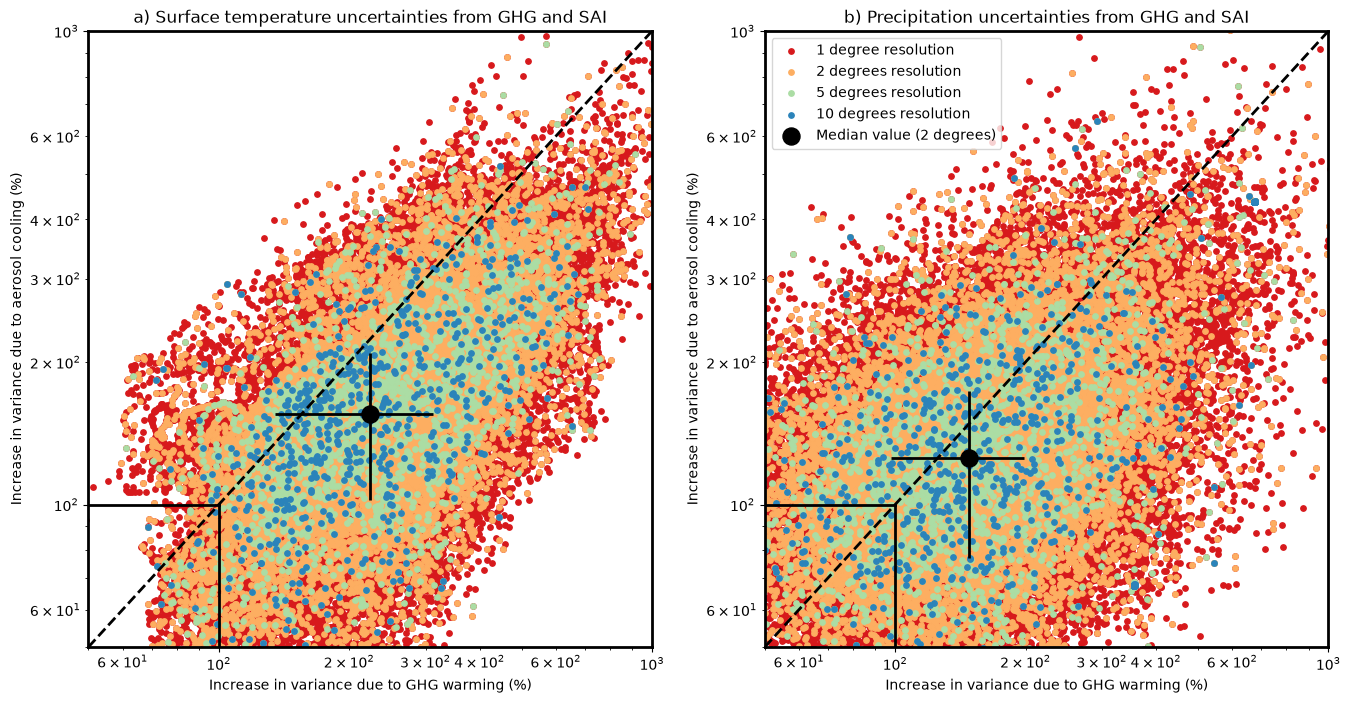

In [1]:
import sys
import os as _os
_r = _os.getcwd()
while not _os.path.isdir(_os.path.join(_r, "python")) and _os.path.dirname(_r) != _r:
    _r = _os.path.dirname(_r)
_os.chdir(_r)   # notebooks live in j_notebooks/; anchor to project root
sys.path.insert(0, "python")
import numpy as np
import matplotlib.pyplot as plt
import mat_utils as mu
from mat_utils import brewermap


def load_res(deg, var):
    """Load a resolution file. 2deg_pr is regenerated in-folder -> npz."""
    if deg == "2" and var == "pr":
        d = mu.load_npz("2deg_pr")
    else:
        d = mu.loadmat(f"{deg}deg_{var}.mat")
    return (np.asarray(d["sola_st"], float).ravel(),
            np.asarray(d["ssp_st"], float).ravel(),
            np.asarray(d["sulf_st"], float).ravel())


fc = brewermap(4, "Spectral")
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 8))

# NOTE: figure creation and ALL plotting must stay in ONE cell. With the inline
# backend, a figure is displayed (and closed) at the end of the cell that
# created it, so splitting the scatters into later cells yields an empty figure.

# --- Surface temperature panel ---
for k, deg in enumerate(["1", "2", "5", "10"]):
    sola, ssp, sulf = load_res(deg, "tas")
    ax1.scatter(np.abs(ssp) / sola * 100, np.abs(sulf) / sola * 100, s=15,
                color=fc[k])
sola2, ssp2, sulf2 = load_res("2", "tas")
ssp_r = np.abs(ssp2) / sola2 * 100
sul_r = np.abs(sulf2) / sola2 * 100
ax1.scatter(np.nanmedian(ssp_r), np.nanmedian(sul_r), s=150, c="k")
ax1.errorbar(np.nanmedian(ssp_r), np.nanmedian(sul_r),
             xerr=np.nanpercentile(ssp_r, 2), yerr=np.nanpercentile(sul_r, 2),
             color="k", linewidth=2)
ax1.plot([50, 1000], [50, 1000], "k--", linewidth=2)
ax1.plot([50, 100], [100, 100], "k-", linewidth=2)
ax1.plot([100, 100], [50, 100], "k-", linewidth=2)
ax1.set_xscale("log"); ax1.set_yscale("log")
ax1.set_xlim(50, 1000); ax1.set_ylim(50, 1000)
ax1.set_xlabel("Increase in variance due to GHG warming (%)")
ax1.set_ylabel("Increase in variance due to aerosol cooling (%)")
ax1.set_title("a) Surface temperature uncertainties from GHG and SAI", color="k")
for s in ax1.spines.values():
    s.set_linewidth(2)

# --- Precipitation panel (2deg from the regenerated 2deg_pr.npz) ---
labels = ["1 degree resolution", "2 degrees resolution", "5 degrees resolution",
          "10 degrees resolution"]
for k, deg in enumerate(["1", "2", "5", "10"]):
    sola, ssp, sulf = load_res(deg, "pr")
    ax2.scatter(np.abs(ssp) / sola * 100, np.abs(sulf) / sola * 100, s=15,
                color=fc[k], label=labels[k])
sola2, ssp2, sulf2 = load_res("2", "pr")
ssp_r = np.abs(ssp2) / sola2 * 100
sul_r = np.abs(sulf2) / sola2 * 100
ax2.scatter(np.nanmedian(ssp_r), np.nanmedian(sul_r), s=150, c="k",
            label="Median value (2 degrees)")
ax2.errorbar(np.nanmedian(ssp_r), np.nanmedian(sul_r),
             xerr=np.nanpercentile(ssp_r, 2), yerr=np.nanpercentile(sul_r, 2),
             color="k", linewidth=2)
ax2.plot([50, 1000], [50, 1000], "k--", linewidth=2)
ax2.plot([50, 100], [100, 100], "k-", linewidth=2)
ax2.plot([100, 100], [50, 100], "k-", linewidth=2)
ax2.set_xscale("log"); ax2.set_yscale("log")
ax2.set_xlim(50, 1000); ax2.set_ylim(50, 1000)
ax2.set_xlabel("Increase in variance due to GHG warming (%)")
ax2.set_ylabel("Increase in variance due to aerosol cooling (%)")
ax2.set_title("b) Precipitation uncertainties from GHG and SAI", color="k")
ax2.legend(loc="upper left")
for s in ax2.spines.values():
    s.set_linewidth(2)
fig.set_facecolor("w")
plt.show()

In [2]:
import os
os.makedirs("py_outputs", exist_ok=True)
fig.savefig("py_outputs/GeoMIP_spatial_uncertainties.png", dpi=300, bbox_inches="tight")
print("saved py_outputs/GeoMIP_spatial_uncertainties.png")

saved py_outputs/GeoMIP_spatial_uncertainties.png
